# Activité pratique n°3 — RAG multimodal agentique

**Nom :** Mohamed Ouallal  

**Classe :** IADATA — Groupe 4  


## Étape 1 — Extraction du texte et des images


In [1]:
import sys
from pathlib import Path
import pymupdf
from IPython.display import display
from PIL import Image
from rag_pipeline import extraire_pdf

assert sys.version_info[:2] == (3, 11), "Choisir le noyau Python 3.11 de .venv."
assert sys.prefix != sys.base_prefix, "Choisir l’environnement virtuel du projet."

# Le notebook est exécuté depuis le dossier projet_rag.
PDF_PATH = Path("attention is all you need.pdf")
OUTPUT_DIR = Path("resultats_pdf")
print("Python :", sys.version.split()[0])
print("PyMuPDF :", pymupdf.VersionBind)
print("PDF :", PDF_PATH.name)


Python : 3.11.18
PyMuPDF : 2.1
PDF : attention is all you need.pdf


In [2]:
resultats = extraire_pdf(PDF_PATH, OUTPUT_DIR)

print("Pages traitées :", len(resultats["pages"]))
print("Images enregistrées :", len(resultats["images"]))
print("Texte complet :", resultats["texte_complet"])
print()
for page in resultats["pages"]:
    print(f"Page {page['page']:2d} : {len(page['texte']):5d} caractères — {page['chemin'].name}")

pages_sans_texte = [page["page"] for page in resultats["pages"] if not page["texte"].strip()]
print("Pages sans texte :", pages_sans_texte)


Pages traitées : 11
Images enregistrées : 3
Texte complet : resultats_pdf/texte_complet.txt

Page  1 :  3275 caractères — page_001.txt
Page  2 :  4310 caractères — page_002.txt
Page  3 :  1832 caractères — page_003.txt
Page  4 :  2629 caractères — page_004.txt
Page  5 :  3460 caractères — page_005.txt
Page  6 :  3865 caractères — page_006.txt
Page  7 :  3315 caractères — page_007.txt
Page  8 :  3820 caractères — page_008.txt
Page  9 :  4058 caractères — page_009.txt
Page 10 :  3274 caractères — page_010.txt
Page 11 :  2471 caractères — page_011.txt
Pages sans texte : []


### Aperçu du texte


In [3]:
print(resultats["pages"][0]["texte"][:2000])


             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com


                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propose a new simple network architecture, the Transfo

### Aperçu des images


Page 3 — page_003_image_94.png


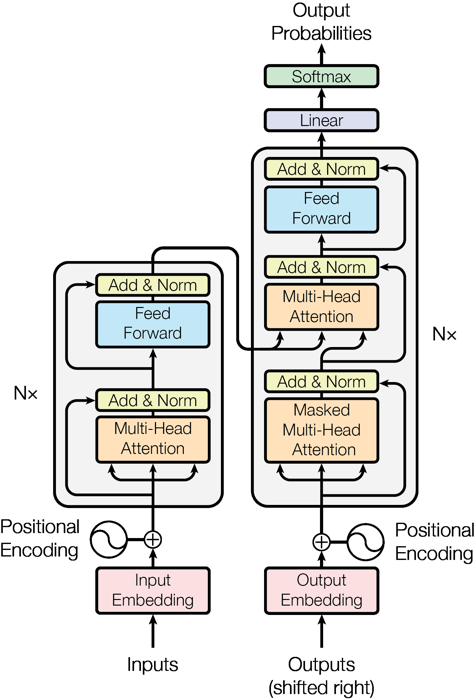

Page 4 — page_004_image_102.png


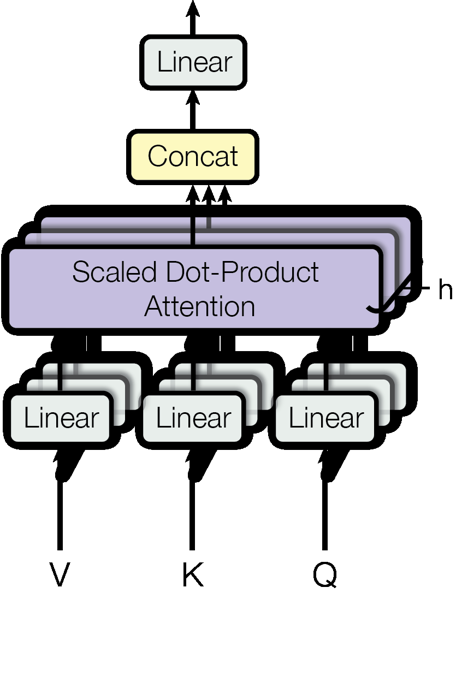

Page 4 — page_004_image_104.png


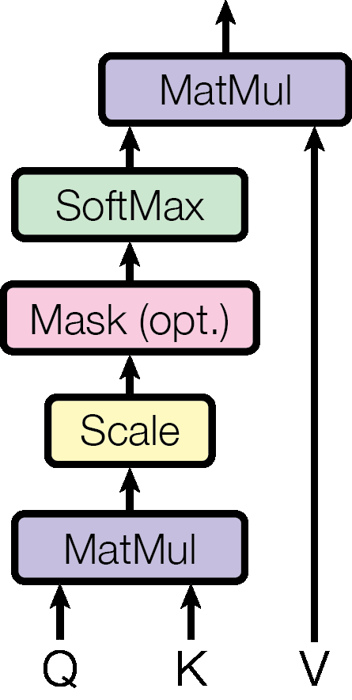

In [4]:
for image_info in resultats["images"]:
    print(f"Page {image_info['page']} — {image_info['chemin'].name}")
    with Image.open(image_info["chemin"]) as image:
        apercu = image.convert("RGB")
        apercu.thumbnail((700, 700))
        display(apercu)


## Étape 2 — Embeddings multimodaux avec CLIP


### Chargement du modèle


In [5]:
import torch
from rag_pipeline import EncodeurCLIP, decouper_texte

encodeur = EncodeurCLIP()
print("Modèle :", encodeur.nom_modele)
print("Poids :", encodeur.poids)
print("Appareil :", encodeur.appareil)
print("Longueur de contexte :", encodeur.tokenizer.context_length)


/Users/mohamedouallal/emsi/5IIR/IAGEN/partie3/projet_rag/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modèle : ViT-B-32
Poids : laion2b_s34b_b79k
Appareil : cpu
Longueur de contexte : 77


### Découpage du texte


In [6]:
fragments = []
for page in resultats["pages"]:
    textes_page = decouper_texte(page["texte"], encodeur.tokenizer,
                                 taille=60, chevauchement=10)
    for numero_fragment, texte in enumerate(textes_page):
        fragments.append({
            "page": page["page"],
            "fragment": numero_fragment,
            "texte": texte,
            "source": str(page["chemin"])
        })

tailles = [len(encodeur.tokenizer.encode(f["texte"])) for f in fragments]
print("Nombre de fragments :", len(fragments))
print("Tokens par fragment (min / max) :", min(tailles), "/", max(tailles))
print("Page du premier fragment :", fragments[0]["page"])
print(fragments[0]["texte"])
assert max(tailles) <= 60


Nombre de fragments : 170
Tokens par fragment (min / max) : 12 / 60
Page du premier fragment : 1
Attention Is All You Need Ashish Vaswani∗ Noam Shazeer∗ Niki Parmar∗ Jakob Uszkoreit∗ Google Brain Google Brain Google Research Google Research avaswani@google.com noam@google.com nikip@google.com


### Encodage du texte et des images


In [7]:
embeddings_textes = encodeur.encoder_textes([f["texte"] for f in fragments])
embeddings_images = encodeur.encoder_images([i["chemin"] for i in resultats["images"]])

print("Embeddings texte :", tuple(embeddings_textes.shape))
print("Embeddings image :", tuple(embeddings_images.shape))
print("Premières composantes du premier texte :", embeddings_textes[0, :5].tolist())
print("Premières composantes de la première image :", embeddings_images[0, :5].tolist())


Embeddings texte : (170, 512)
Embeddings image : (3, 512)
Premières composantes du premier texte : [0.001987872179597616, 0.012549949809908867, -0.11136806011199951, 0.0025061301421374083, 0.011696447618305683]
Premières composantes de la première image : [0.03023671731352806, -0.13937994837760925, -0.002614443888887763, -0.032461851835250854, 0.002437469083815813]


### Vérification de la normalisation


In [8]:
assert embeddings_textes.shape == (len(fragments), 512)
assert embeddings_images.shape == (len(resultats["images"]), 512)
for nom, vecteurs in [("Texte", embeddings_textes), ("Image", embeddings_images)]:
    normes = vecteurs.norm(dim=-1)
    assert torch.isfinite(vecteurs).all()
    assert torch.allclose(normes, torch.ones_like(normes), atol=1e-5)
    print(f"{nom} — norme min : {normes.min().item():.6f}, max : {normes.max().item():.6f}")
print("Les deux types de contenu sont représentés dans le même espace de 512 dimensions.")


Texte — norme min : 1.000000, max : 1.000000
Image — norme min : 1.000000, max : 1.000000
Les deux types de contenu sont représentés dans le même espace de 512 dimensions.


### Sauvegarde des embeddings


In [9]:
import json

torch.save({"textes": embeddings_textes, "images": embeddings_images},
           OUTPUT_DIR / "embeddings_clip.pt")
informations = {
    "modele": encodeur.nom_modele,
    "poids": encodeur.poids,
    "taille_fragment": 60,
    "chevauchement_max": 10,
    "fragments": fragments,
    "images": [{"page": image["page"], "source": str(image["chemin"])}
               for image in resultats["images"]]
}
(OUTPUT_DIR / "embeddings_clip.json").write_text(
    json.dumps(informations, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Embeddings :", OUTPUT_DIR / "embeddings_clip.pt")
print("Fragments et références :", OUTPUT_DIR / "embeddings_clip.json")


Embeddings : resultats_pdf/embeddings_clip.pt
Fragments et références : resultats_pdf/embeddings_clip.json
